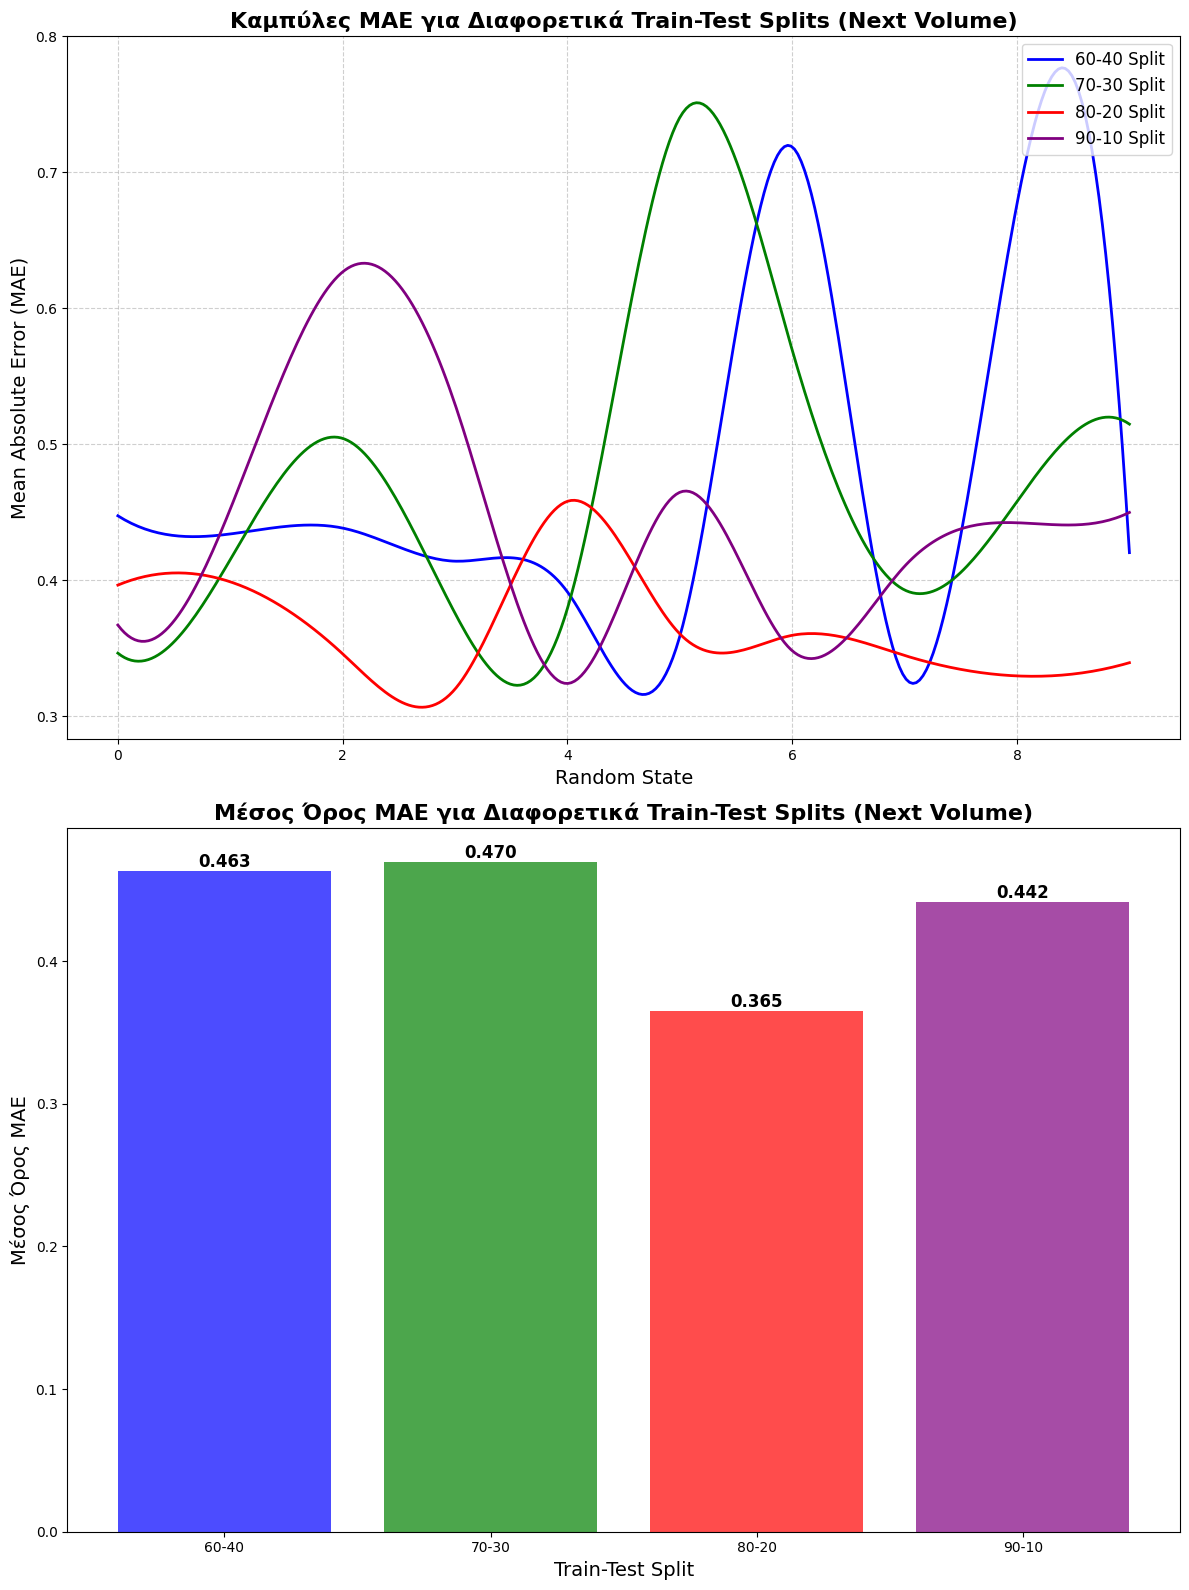

In [1]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 = np.array([
    0.4474718963372552, 0.4341223192218877, 0.43844979227020775,
    0.4141081167041595, 0.3915101551354897, 0.35894511484241853,
    0.7186699036469402, 0.3288181968210865, 0.6768764075035094,
    0.4203760079016513
])
mae_70_30 = np.array([
    0.34651002379696655, 0.41525471590393337, 0.5043825542217908,
    0.3758014748536685, 0.3793681171149302, 0.7403298828901531,
    0.5692486594930576, 0.39293028615956743, 0.4580368485433882,
    0.5148602451103934
])
mae_80_20 = np.array([
    0.3965239126762181, 0.3989434576961213, 0.3459975079857034,
    0.32009732347908065, 0.458133146108967, 0.3606541757211808,
    0.3596194550057728, 0.3447853865916641, 0.32976301863791435,
    0.3394721285200874
])
mae_90_10 = np.array([
    0.36715429493848745, 0.4523805911197632, 0.6267580881677042,
    0.529455423364205, 0.32419822210368765, 0.46476620915480404,
    0.34826570948191043, 0.4103979855800496, 0.4423577914985962,
    0.4499502580523133
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)


axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Next Volume)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Next Volume)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
